# Практическая работа № 10 — уровень C

Сравнение K-Means, DBSCAN и иерархической кластеризации на данных сложной невыпуклой формы `make_moons`. Метка генератора используется только для внешней проверки качества.

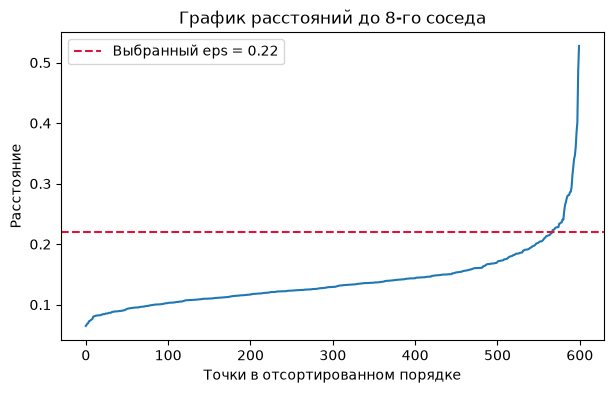

,Кластеров,Шум,Силуэт,ARI
Метод,,,,
K-Means,2,0,0.4923,0.4570
DBSCAN,2,8,0.3925,0.9735
Иерархическая (single),2,0,0.3847,0.9933


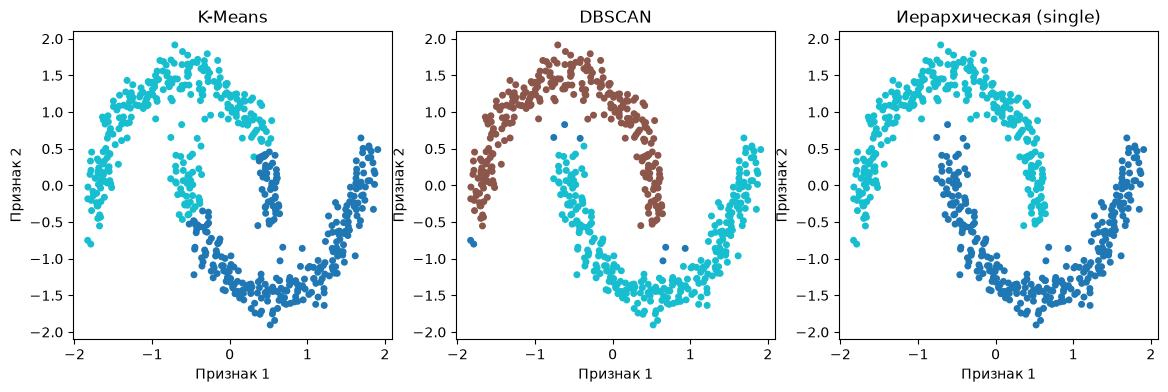

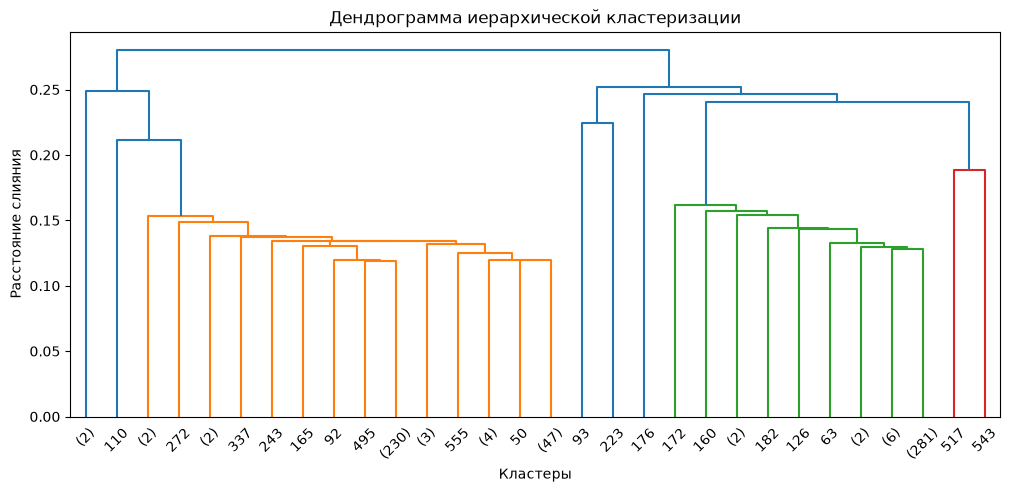

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.datasets import make_moons
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

X_raw, y_reference = make_moons(n_samples=600, noise=0.08, random_state=42)
X = StandardScaler().fit_transform(X_raw)
labels_kmeans = KMeans(n_clusters=2, n_init=20, random_state=42).fit_predict(X)
labels_hier = AgglomerativeClustering(n_clusters=2, linkage='single').fit_predict(X)

MIN_SAMPLES, EPS = 8, 0.22
distances = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X).kneighbors(X)[0]
k_distances = np.sort(distances[:, -1])
plt.figure(figsize=(7, 4))
plt.plot(k_distances); plt.axhline(EPS, color='crimson', linestyle='--', label=f'Выбранный eps = {EPS}')
plt.title('График расстояний до 8-го соседа'); plt.xlabel('Точки в отсортированном порядке'); plt.ylabel('Расстояние'); plt.legend(); plt.show()

labels_dbscan = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(X)
results = {'K-Means': labels_kmeans, 'DBSCAN': labels_dbscan, 'Иерархическая (single)': labels_hier}
rows = []
for name, labels in results.items():
    core = labels != -1
    rows.append({'Метод': name, 'Кластеров': len(set(labels[core])), 'Шум': int((~core).sum()),
                 'Силуэт': silhouette_score(X[core], labels[core]), 'ARI': adjusted_rand_score(y_reference, labels)})
display(pd.DataFrame(rows).set_index('Метод').round(4))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, labels) in zip(axes, results.items()):
    ax.scatter(X[:, 0], X[:, 1], c=labels, cmap='tab10', s=16)
    ax.set(title=name, xlabel='Признак 1', ylabel='Признак 2')
plt.show()

linkage_matrix = linkage(X, method='single')
plt.figure(figsize=(12, 5))
dendrogram(linkage_matrix, truncate_mode='lastp', p=30, show_leaf_counts=True)
plt.title('Дендрограмма иерархической кластеризации'); plt.xlabel('Кластеры'); plt.ylabel('Расстояние слияния'); plt.show()

## Вывод

K-Means даёт более высокий силуэт, но неверно режет две изогнутые луны. DBSCAN с `eps=0.22` и `min_samples=8` находит два кластера и выделяет пограничные точки как шум; его ARI около 0.97. Иерархическая кластеризация с одиночной связью лучше всего восстанавливает форму лун (ARI около 0.99), но чувствительна к шуму и эффекту цепочек. Дендрограмма показывает порядок и расстояния слияния групп — информацию, которой нет в плоском разбиении.